Train: 28417 | Val: 4060 | Test: 8120

--- XGBOOST METRİK TABLOSU ---
            Accuracy  Precision    Recall  F1-score
Train       0.920681   0.915618  0.919376  0.916393
Validation  0.897783   0.889067  0.895277  0.891251
Test        0.899631   0.891550  0.893534  0.891491


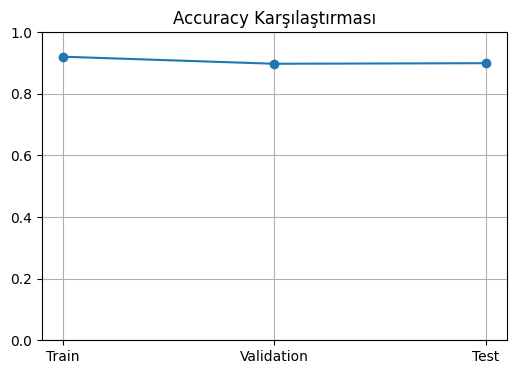

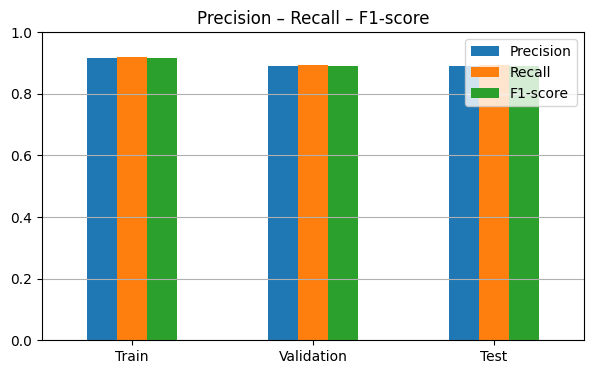

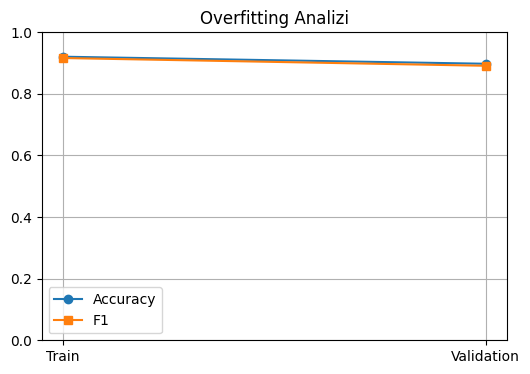

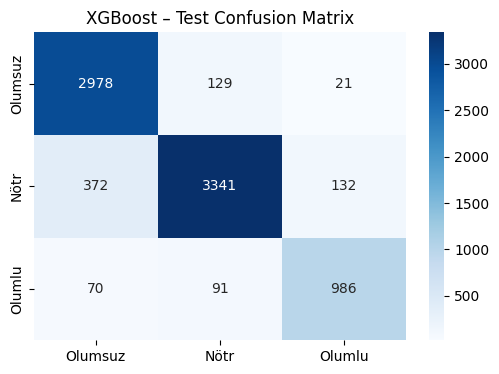

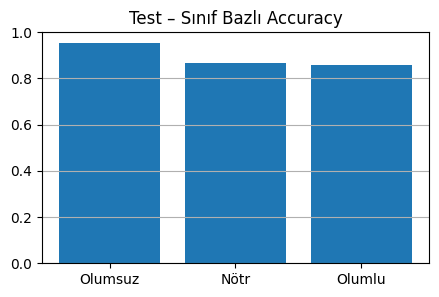

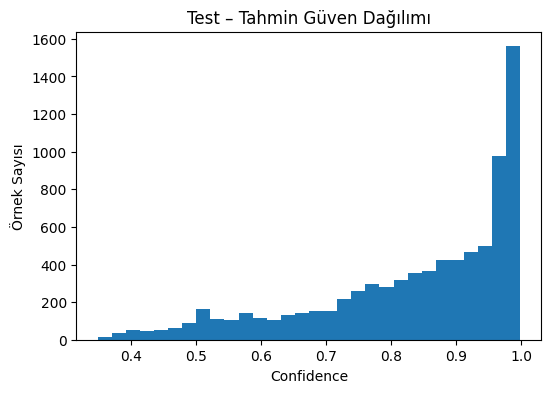

In [1]:
# ===================================================
# 0) KÜTÜPHANELER
# ===================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

from xgboost import XGBClassifier

# ===================================================
# 1) VERİ YÜKLEME
# ===================================================
df = pd.read_csv("Turkish-Review-Sentiment-Data.csv")
df.columns = [c.lower() for c in df.columns]

TEXT_COL  = "review"
LABEL_COL = "sentiment"

# ===================================================
# 2) LABEL MAP
# ===================================================
label_map = {
    "olumsuz":0, "negatif":0,
    "nötr":1, "notr":1, "neutral":1,
    "olumlu":2, "pozitif":2, "positive":2
}

df[LABEL_COL] = (
    df[LABEL_COL].astype(str)
    .str.lower()
    .map(label_map)
    .fillna(1)
    .astype(int)
)

# ===================================================
# 3) METİN TEMİZLEME
# ===================================================
def clean(x):
    return "" if pd.isna(x) else str(x).lower().replace("\n"," ").strip()

df[TEXT_COL] = df[TEXT_COL].apply(clean)

# ===================================================
# 4) TRAIN (%70) / TEMP (%30)
# ===================================================
X_train, X_temp, y_train, y_temp = train_test_split(
    df[TEXT_COL], df[LABEL_COL],
    test_size=0.30,
    random_state=42,
    stratify=df[LABEL_COL]
)

# ===================================================
# 5) TEMP → VALIDATION (%10) + TEST (%20)
# ===================================================
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=2/3,     # 20 test – 10 val
    random_state=42,
    stratify=y_temp
)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# ===================================================
# 6) TF-IDF
# ===================================================
tfidf = TfidfVectorizer(
    max_features=40000,
    ngram_range=(1,2),
    min_df=5,
    max_df=0.9
)

Xtr = tfidf.fit_transform(X_train)
Xva = tfidf.transform(X_val)
Xte = tfidf.transform(X_test)

# ===================================================
# 7) XGBOOST MODEL
# ===================================================
xgb = XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    random_state=42
)

xgb.fit(Xtr, y_train)

# ===================================================
# 8) TAHMİNLER
# ===================================================
pred_train = xgb.predict(Xtr)
pred_val   = xgb.predict(Xva)
pred_test  = xgb.predict(Xte)

# ===================================================
# 9) METRİK TABLOSU
# ===================================================
def metrics(y, p):
    acc = accuracy_score(y, p)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro")
    return acc, pr, rc, f1

metrics_df = pd.DataFrame({
    "Accuracy":[
        metrics(y_train,pred_train)[0],
        metrics(y_val,pred_val)[0],
        metrics(y_test,pred_test)[0]
    ],
    "Precision":[
        metrics(y_train,pred_train)[1],
        metrics(y_val,pred_val)[1],
        metrics(y_test,pred_test)[1]
    ],
    "Recall":[
        metrics(y_train,pred_train)[2],
        metrics(y_val,pred_val)[2],
        metrics(y_test,pred_test)[2]
    ],
    "F1-score":[
        metrics(y_train,pred_train)[3],
        metrics(y_val,pred_val)[3],
        metrics(y_test,pred_test)[3]
    ]
}, index=["Train","Validation","Test"])

print("\n--- XGBOOST METRİK TABLOSU ---")
print(metrics_df)

# ===================================================
# ========== TÜM ANALİZ GRAFİKLERİ (EN ALT) ==========
# ===================================================

# 1) Accuracy Karşılaştırması
plt.figure(figsize=(6,4))
plt.plot(metrics_df.index, metrics_df["Accuracy"], marker="o")
plt.title("Accuracy Karşılaştırması")
plt.ylim(0,1)
plt.grid(True)
plt.show()

# 2) Precision – Recall – F1
metrics_df[["Precision","Recall","F1-score"]].plot(kind="bar", figsize=(7,4))
plt.title("Precision – Recall – F1-score")
plt.ylim(0,1)
plt.grid(axis="y")
plt.xticks(rotation=0)
plt.show()

# 3) Train vs Validation (Overfitting)
plt.figure(figsize=(6,4))
plt.plot(["Train","Validation"],
         metrics_df.loc[["Train","Validation"],"Accuracy"],
         marker="o", label="Accuracy")
plt.plot(["Train","Validation"],
         metrics_df.loc[["Train","Validation"],"F1-score"],
         marker="s", label="F1")
plt.title("Overfitting Analizi")
plt.ylim(0,1)
plt.grid(True)
plt.legend()
plt.show()

# 4) Confusion Matrix – Test
plt.figure(figsize=(6,4))
sns.heatmap(
    confusion_matrix(y_test, pred_test),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=["Olumsuz","Nötr","Olumlu"],
    yticklabels=["Olumsuz","Nötr","Olumlu"]
)
plt.title("XGBoost – Test Confusion Matrix")
plt.show()

# 5) Sınıf Bazlı Accuracy – Test
class_acc = []
y_test_np = np.array(y_test)
pred_test_np = np.array(pred_test)

for cls in [0,1,2]:
    mask = (y_test_np == cls)
    class_acc.append(accuracy_score(y_test_np[mask], pred_test_np[mask]))

plt.figure(figsize=(5,3))
plt.bar(["Olumsuz","Nötr","Olumlu"], class_acc)
plt.title("Test – Sınıf Bazlı Accuracy")
plt.ylim(0,1)
plt.grid(axis="y")
plt.show()

# 6) Confidence Dağılımı – Test
probs = xgb.predict_proba(Xte)
confidence = np.max(probs, axis=1)

plt.figure(figsize=(6,4))
plt.hist(confidence, bins=30)
plt.title("Test – Tahmin Güven Dağılımı")
plt.xlabel("Confidence")
plt.ylabel("Örnek Sayısı")
plt.show()
